<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI — Vector Gateway Interface" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and provenance](README.md)

# 01 · Which IVV equity weights changed between two year-end snapshots?

A holding's portfolio weight can change even when its identity stays the same. We will read IVV at **2024-12-31** and **2025-12-31**, establish which equity identifiers can be compared, and find changes large enough to pass a chosen threshold.

These are public iShares historical holdings, retrieved live through the real worker. The investigation describes reported portfolio weights. It does not infer trades, turnover, returns or causes, and it is not an investment recommendation. Cash and derivative lines remain in the coverage diagnostics but are outside the equity comparison.

## Choose a reporting threshold

`MIN_CHANGE_PP` is the minimum absolute change in **percentage points** for a matched equity ISIN. Accept 0.05–2.0 pp. A weight moving from 2.0% to 2.3% changes by +0.3 pp; that is not a 0.3% security return.

The two dates and IVV fund selector are fixed, bounded requests. Change only **0.20 → 0.50 pp** in the final experiment. Predict fewer qualifying matched identifiers while source inventory and join coverage remain unchanged, unless the historical source is revised. Restart the kernel and Run All after editing.

In [1]:
MIN_CHANGE_PP = 0.20  # Percentage points; accepted 0.05–2.0; experiment: 0.50

In [2]:
import hashlib
import os
from datetime import datetime, timezone

import haybarn
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

assert type(MIN_CHANGE_PP) in (int,float) and 0.05 <= MIN_CHANGE_PP <= 2.0
os.environ["PLOOMBER_STATS_ENABLED"]="false"
sns.set_theme(style="whitegrid",context="notebook")
plt.rcParams.update({"figure.dpi":125,"text.parse_math":False,"axes.spines.top":False,"axes.spines.right":False})
def prose(text):display(Markdown(text))
def finish(fig):
    fig.text(.01,.01,f"Source: iShares IVV historical holdings · 2024-12-31 → 2025-12-31 · retrieved {retrieved_at[:10]} UTC · equity ISIN groups",fontsize=8,color="#555555")
    fig.tight_layout(rect=(0,.06,1,.98));plt.show()
con=haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline


Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-etf-ishares/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-etf-ishares/notebooks/pyproject.toml.

## Attach a published native worker and materialize two snapshots

The literal pinned release downloads the matching native binary and verifies its published SHA-256. No worker checkout or Bun build is required. Only `fund_ticker = 'IVV'` is pushed to the two scans; the remaining analytics operate on local tables. This also avoids the v0.4.0 limitation with nonpartition holdings filters.

`AT` selects one calendar-date coordinate, not a date range. DATE has no timezone. The worker uses iShares' payload date when present and otherwise falls back to the requested date; its `as_of_date` is therefore a resolved coordinate, not independent proof that the endpoint supplied a date. We check it matches each requested snapshot and stop on empty results. There is no synthetic fallback.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'ishares' AS ish (
    TYPE vgi,
    LOCATION 'github-auto://Query-farm/vgi-etf-ishares@v0.4.0'
);

,Success


In [4]:
request_started=datetime.now(timezone.utc).isoformat()

In [5]:
%%sql
CREATE TABLE holdings_2024 AS
SELECT * FROM ish.main.holdings AT (TIMESTAMP => DATE '2024-12-31') WHERE fund_ticker='IVV';
CREATE TABLE holdings_2025 AS
SELECT * FROM ish.main.holdings AT (TIMESTAMP => DATE '2025-12-31') WHERE fund_ticker='IVV';
CREATE TABLE snapshots AS
SELECT DATE '2024-12-31' AS requested_date,* FROM holdings_2024
UNION ALL
SELECT DATE '2025-12-31' AS requested_date,* FROM holdings_2025;

,Count


In [6]:
retrieved_at=datetime.now(timezone.utc).isoformat()

## Check coverage before joining

A missing ticker is not a zero-weight position, and a missing ISIN cannot safely be matched on a convenient name. We keep all holding lines in the diagnostics. For the comparison, equity groups need a nonempty ISIN and complete weights; all rows of a repeated ISIN are summed explicitly, preventing a many-to-many join.

Weights already express percent points. We neither normalize totals to 100 nor treat missing weights on cash/futures as zero. iShares explains that holdings values can differ from NAV valuation and its accounting book; see the [official IVV holdings notes](https://www.ishares.com/us/products/239726/ishares-core-sp-500-etf#holdings).

In [7]:
%%sql coverage <<
SELECT requested_date,asset_class,count(*) AS lines,
       min(as_of_date) AS first_resolved_date,max(as_of_date) AS last_resolved_date,
       count(*) FILTER (WHERE as_of_date IS NULL OR as_of_date<>requested_date) AS date_mismatches,
       count(*) FILTER (WHERE isin IS NULL OR trim(isin)='') AS missing_isins,
       count(*) FILTER (WHERE weight_percent IS NULL) AS missing_weights,
       sum(weight_percent) AS reported_weight_percent
FROM snapshots GROUP BY requested_date,asset_class ORDER BY requested_date,asset_class;

In [8]:
display(coverage)
assert set(pd.to_datetime(coverage.requested_date).dt.strftime("%Y-%m-%d"))=={"2024-12-31","2025-12-31"}, "Required snapshot unavailable."
assert coverage.date_mismatches.eq(0).all(), "Worker-resolved date differs from the requested coordinate."
assert coverage.loc[coverage.asset_class.eq("Equity")].groupby("requested_date").lines.sum().gt(0).all()
prose(f"Retrieved UTC: **{request_started} → {retrieved_at}**. "
      f"The two snapshots contain **{int(coverage.lines.sum()):,} holding lines**, including "
      f"**{int(coverage.missing_weights.sum())} missing weights**. Missing measurements stay outside sums; the category table shows their location before we narrow to equities.")

,requested_date,asset_class,lines,first_resolved_date,last_resolved_date,date_mismatches,missing_isins,missing_weights,reported_weight_percent
0,2024-12-31,Cash,2,2024-12-31,2024-12-31,0,2,1,0.07
1,2024-12-31,Cash Collateral and Margins,1,2024-12-31,2024-12-31,0,1,0,0.01
2,2024-12-31,Equity,503,2024-12-31,2024-12-31,0,0,0,99.77
3,2024-12-31,Futures,1,2024-12-31,2024-12-31,0,1,1,NaN
4,2024-12-31,Money Market,1,2024-12-31,2024-12-31,0,0,0,0.15
5,2025-12-31,Cash,2,2025-12-31,2025-12-31,0,2,1,0.06
6,2025-12-31,Cash Collateral and Margins,1,2025-12-31,2025-12-31,0,1,0,0.01
7,2025-12-31,Equity,503,2025-12-31,2025-12-31,0,0,0,99.85
8,2025-12-31,Futures,1,2025-12-31,2025-12-31,0,1,1,NaN
9,2025-12-31,Money Market,1,2025-12-31,2025-12-31,0,0,0,0.12


Retrieved UTC: **2026-11-14T06:27:38.861130+00:00 → 2026-11-14T06:27:40.264548+00:00**. The two snapshots contain **1,016 holding lines**, including **4 missing weights**. Missing measurements stay outside sums; the category table shows their location before we narrow to equities.

In [9]:
%%sql
CREATE TABLE equity_groups AS
SELECT requested_date,isin,min(ticker) AS ticker,min(name) AS name,count(*) AS holding_lines,
       count(*) FILTER (WHERE weight_percent IS NULL) AS missing_weights,
       sum(weight_percent) AS weight_percent
FROM snapshots WHERE asset_class='Equity' AND isin IS NOT NULL AND trim(isin)<>''
GROUP BY requested_date,isin;

,Count


In [10]:
%%sql group_quality <<
SELECT requested_date,count(*) AS equity_isins,
       sum(holding_lines) AS grouped_equity_lines,
       count(*) FILTER (WHERE holding_lines>1) AS repeated_isin_groups,
       count(*) FILTER (WHERE missing_weights>0) AS incomplete_weight_groups,
       sum(weight_percent) AS grouped_weight_percent
FROM equity_groups GROUP BY requested_date ORDER BY requested_date;

In [11]:
display(group_quality)
assert len(group_quality)==2 and group_quality.equity_isins.gt(0).all()
assert group_quality.incomplete_weight_groups.eq(0).all(), "An equity ISIN has incomplete weights; inspect before comparing sums."
raw=con.execute("SELECT * FROM snapshots ORDER BY requested_date,isin,name,ticker,weight_percent,market_value").fetchdf()
source_hash=hashlib.sha256(raw.to_json(orient="records",date_format="iso").encode()).hexdigest()
prose(f"Snapshot fingerprint: `{source_hash}`. Repeated ISIN groups, if present, are aggregated within each date. An ISIN change can still break an economic identity across dates; no issuer-level continuity is assumed.")

,requested_date,equity_isins,grouped_equity_lines,repeated_isin_groups,incomplete_weight_groups,grouped_weight_percent
0,2024-12-31,503,503.0,0,0,99.77
1,2025-12-31,503,503.0,0,0,99.85


Snapshot fingerprint: `8efca7abefe08fa61713886ee64635567612ce3dfab6c7e4bc00cb9b7dd6e26d`. Repeated ISIN groups, if present, are aggregated within each date. An ISIN change can still break an economic identity across dates; no issuer-level continuity is assumed.

## Keep one-sided identifiers visible

A full outer join separates matched ISINs from identifiers observed in only one snapshot. A one-sided row is **not assigned a zero comparison weight**: it may reflect a changed identifier, changed scope, missing source coverage or an actual portfolio change. The labels below say only what these two snapshots show.

The first chart compares weights only where both measurements exist. The diagonal means unchanged weight; distance above or below it gives the direction of change.

In [12]:
%%sql
CREATE TABLE compared AS
SELECT coalesce(a.isin,b.isin) AS isin,coalesce(b.ticker,a.ticker) AS ticker,
       coalesce(b.name,a.name) AS name,a.weight_percent AS weight_2024,b.weight_percent AS weight_2025,
       CASE WHEN a.isin IS NULL THEN '2025 only'
            WHEN b.isin IS NULL THEN '2024 only' ELSE 'Both snapshots' END AS coverage_status,
       b.weight_percent-a.weight_percent AS change_pp
FROM (SELECT * FROM equity_groups WHERE requested_date=DATE '2024-12-31') a
FULL OUTER JOIN (SELECT * FROM equity_groups WHERE requested_date=DATE '2025-12-31') b USING(isin);

,Count


In [13]:
%%sql join_coverage <<
SELECT coverage_status,count(*) AS isin_groups,sum(weight_2024) AS observed_2024_weight,
       sum(weight_2025) AS observed_2025_weight
FROM compared GROUP BY coverage_status ORDER BY coverage_status;

In [14]:
%%sql matched <<
SELECT * FROM compared WHERE coverage_status='Both snapshots' ORDER BY isin;

,coverage_status,isin_groups,observed_2024_weight,observed_2025_weight
0,2024 only,19,0.51,NaN
1,2025 only,19,NaN,1.52
2,Both snapshots,484,99.26,98.33


**484 equity ISINs** have both weights. **38** appear in only one snapshot. The join reconciles to each date's grouped equity weight; only the matched set supports a numerical difference.

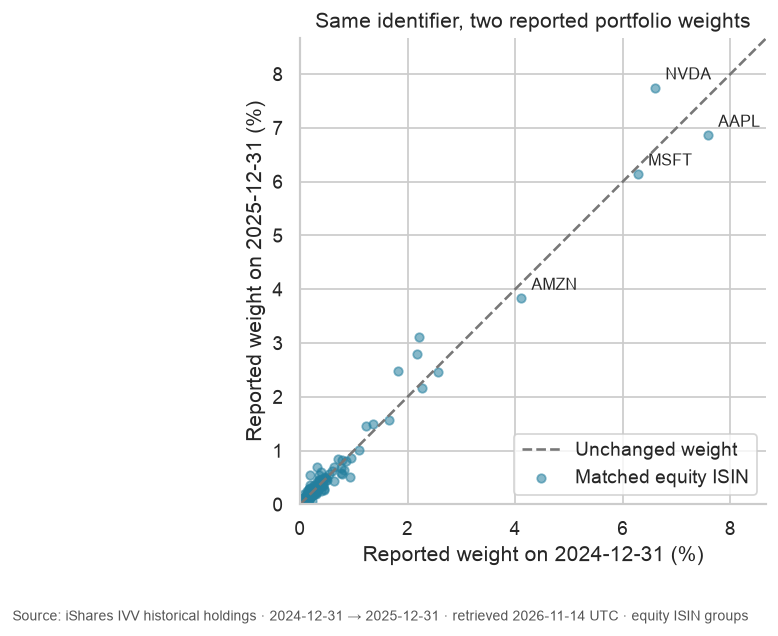

In [15]:
display(join_coverage)
assert not matched.empty and matched["isin"].is_unique
assert matched[["weight_2024","weight_2025","change_pp"]].notna().all().all()
assert np.allclose(matched.weight_2025-matched.weight_2024,matched.change_pp)
assert np.isclose(join_coverage.observed_2024_weight.sum(),group_quality.grouped_weight_percent.iloc[0])
assert np.isclose(join_coverage.observed_2025_weight.sum(),group_quality.grouped_weight_percent.iloc[1])
assert int(join_coverage.loc[join_coverage.coverage_status.ne("2025 only"),"isin_groups"].sum())==int(group_quality.equity_isins.iloc[0])
assert int(join_coverage.loc[join_coverage.coverage_status.ne("2024 only"),"isin_groups"].sum())==int(group_quality.equity_isins.iloc[1])
prose(f"**{len(matched)} equity ISINs** have both weights. "
      f"**{int(join_coverage.loc[join_coverage.coverage_status.ne('Both snapshots'),'isin_groups'].sum())}** appear in only one snapshot. "
      "The join reconciles to each date's grouped equity weight; only the matched set supports a numerical difference.")
fig,ax=plt.subplots(figsize=(8.5,5.2))
limit=max(float(matched.weight_2024.max()),float(matched.weight_2025.max()))*1.12
ax.plot([0,limit],[0,limit],color="#777777",linestyle="--",label="Unchanged weight")
ax.scatter(matched.weight_2024,matched.weight_2025,s=24,alpha=.55,color="#247f9e",label="Matched equity ISIN")
for r in matched.assign(largest=matched[["weight_2024","weight_2025"]].max(axis=1)).nlargest(4,"largest").itertuples():
    ax.annotate(r.ticker or r.isin,(r.weight_2024,r.weight_2025),xytext=(6,5),textcoords="offset points",fontsize=9)
ax.set(xlabel="Reported weight on 2024-12-31 (%)",ylabel="Reported weight on 2025-12-31 (%)",xlim=(0,limit),ylim=(0,limit),title="Same identifier, two reported portfolio weights")
ax.set_aspect("equal",adjustable="box");ax.legend(loc="lower right");finish(fig)

## Apply a threshold to matched changes

Use the absolute change to select both increases and decreases. The signed change retains direction. The threshold includes equality; weights are reported at limited precision, so very small differences should not be overinterpreted.

The chart shows at most the 16 largest absolute qualifying changes for readability. The SQL summary and table describe the full qualifying set. A larger threshold changes this reporting subset, not the holdings acquired or the join.

In [16]:
%%sql selected <<
SELECT isin,ticker,name,weight_2024,weight_2025,change_pp
FROM compared WHERE coverage_status='Both snapshots' AND abs(change_pp)+1e-10 >= {{MIN_CHANGE_PP}}
ORDER BY abs(change_pp) DESC,isin;

In [17]:
%%sql threshold_summary <<
SELECT count(*) AS matched_isins,
       count(*) FILTER (WHERE abs(change_pp)+1e-10 >= {{MIN_CHANGE_PP}}) AS qualifying_isins,
       count(*) FILTER (WHERE change_pp+1e-10 >= {{MIN_CHANGE_PP}}) AS increases,
       count(*) FILTER (WHERE change_pp-1e-10 <= -{{MIN_CHANGE_PP}}) AS decreases,
       max(abs(change_pp)) AS largest_absolute_change_pp
FROM compared WHERE coverage_status='Both snapshots';

,matched_isins,qualifying_isins,increases,decreases,largest_absolute_change_pp
0,484,13,8,5,1.14


,isin,ticker,name,weight_2024,weight_2025,change_pp
0,US67066G1040,NVDA,NVIDIA CORP,6.60,7.74,1.14
1,US02079K3059,GOOGL,ALPHABET INC CLASS A,2.22,3.11,0.89
2,US0378331005,AAPL,APPLE INC,7.58,6.86,-0.72
3,US02079K1079,GOOG,ALPHABET INC CLASS C,1.82,2.49,0.67
4,US11135F1012,AVGO,BROADCOM INC,2.17,2.79,0.62
5,US91324P1021,UNH,UNITEDHEALTH GROUP INC,0.93,0.51,-0.42
6,US69608A1088,PLTR,PALANTIR TECHNOLOGIES INC CLASS A,0.31,0.69,0.38
7,US5951121038,MU,MICRON TECHNOLOGY INC,0.19,0.55,0.36
8,US0231351067,AMZN,AMAZON COM INC,4.11,3.83,-0.28
9,US5324571083,LLY,ELI LILLY,1.22,1.46,0.24


At **0.20 pp**, **13 of 484** matched identifiers qualify: **8 increases** and **5 decreases**. The largest absolute matched change is **1.14 pp**, independent of this reporting cutoff. Price changes, corporate actions, index changes and portfolio transactions can all affect weights; these two snapshots do not separate those causes.

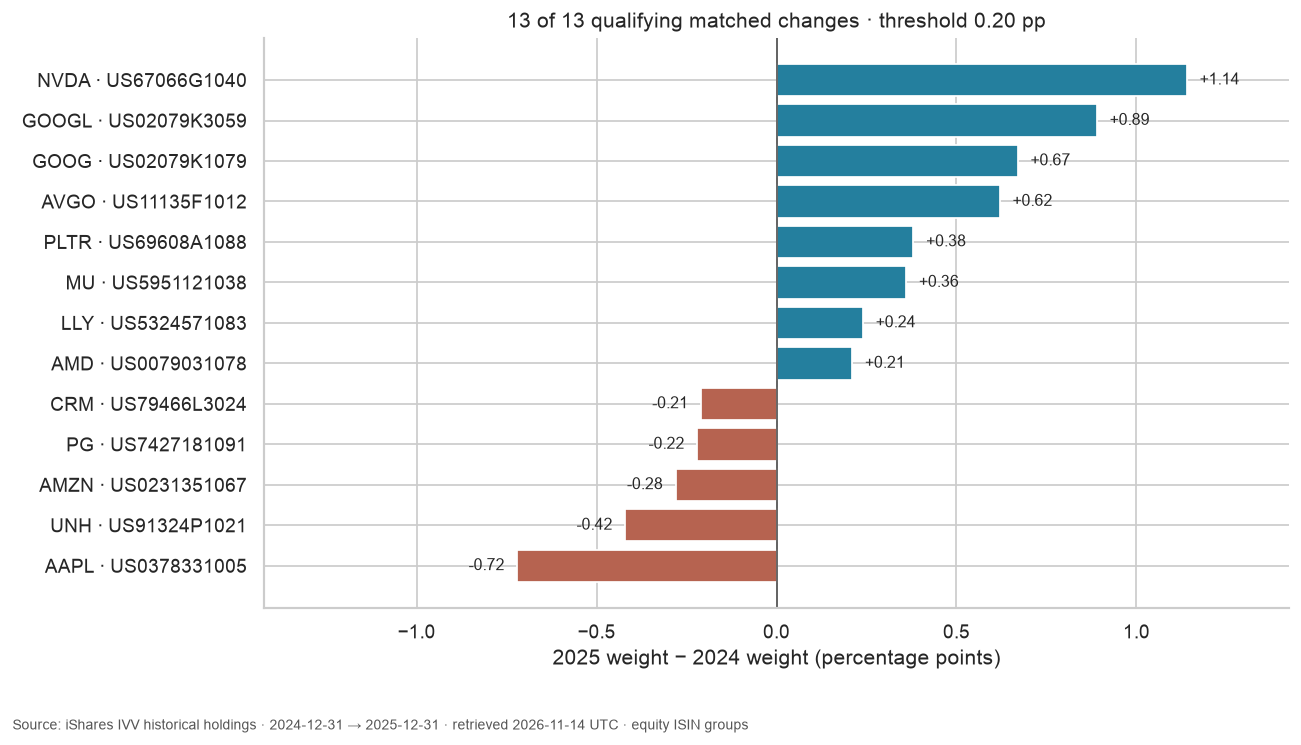

In [18]:
display(threshold_summary)
display(selected)
assert len(selected)==int(threshold_summary.qualifying_isins.iloc[0])
assert len(selected)==int(threshold_summary.increases.iloc[0]+threshold_summary.decreases.iloc[0])
assert selected.change_pp.abs().ge(MIN_CHANGE_PP-1e-10).all()
r=threshold_summary.iloc[0]
prose(f"At **{MIN_CHANGE_PP:.2f} pp**, **{int(r.qualifying_isins)} of {int(r.matched_isins)}** matched identifiers qualify: "
      f"**{int(r.increases)} increases** and **{int(r.decreases)} decreases**. "
      f"The largest absolute matched change is **{r.largest_absolute_change_pp:.2f} pp**, independent of this reporting cutoff. "
      "Price changes, corporate actions, index changes and portfolio transactions can all affect weights; these two snapshots do not separate those causes.")
fig,ax=plt.subplots(figsize=(10.5,6.1))
shown=selected.head(16).sort_values("change_pp")
if shown.empty:
    ax.text(.5,.5,f"No matched changes reach {MIN_CHANGE_PP:.2f} pp",ha="center",va="center",transform=ax.transAxes)
    ax.set_yticks([])
else:
    labels=[f"{r.ticker or 'no ticker'} · {r.isin}" for r in shown.itertuples()]
    ax.barh(labels,shown.change_pp,color=["#247f9e" if x>=0 else "#b66350" for x in shown.change_pp])
    bound=max(MIN_CHANGE_PP,float(shown.change_pp.abs().max()))*1.25
    ax.set_xlim(-bound,bound)
    for i,x in enumerate(shown.change_pp):ax.text(x+(bound*.025 if x>=0 else -bound*.025),i,f"{x:+.2f}",ha="left" if x>=0 else "right",va="center",fontsize=9)
ax.axvline(0,color="#555555",linewidth=1)
ax.set(xlabel="2025 weight − 2024 weight (percentage points)",title=f"{len(shown)} of {len(selected)} qualifying matched changes · threshold {MIN_CHANGE_PP:.2f} pp")
finish(fig)

## One change to test

Change only **`MIN_CHANGE_PP` from `0.20` to `0.50`** in a separate executed copy. Predict that the qualifying count cannot increase. Compare the snapshot fingerprint, category diagnostics and join coverage first: identical inputs isolate the threshold effect. The largest absolute matched change and the scatter plot should remain unchanged. Restore **0.20** afterward.

A reported historical date is not an immutable revision identifier. Future source corrections may change these rows. Missing identifiers are excluded from the ISIN comparison, one-sided observations remain unpaired, and no result estimates fund returns or trading activity.

In [19]:
con.execute("DETACH ish")
con.close()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Notebook setup and provenance](README.md)